# Cross Validation — Python companion
**GSND 5355Q [Machine Learning for Biomedical Data](https://njms.rutgers.edu/sgs/olc/mlbd/index.php), Week 1**

This notebook follows the R lecture `lectures/week2/crossValidation.Rmd` section by section. `caret::knn3` becomes `KNeighborsClassifier`, and `caret::train` with `trainControl` becomes `GridSearchCV`.

> **Note:** Python and R use different random number generators, so splits, resamples, and some numbers below will differ slightly from the R slides. The ideas and conclusions are the same.

## Cross-validation
We use the `mnist_27` data from the R `dslabs` package: handwritten 2s and 7s, summarized by two predictors (`x_1`, `x_2`). `true_p` holds the *true* conditional probability on a grid, so we can see how close each method gets.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Data live in python/data/ in the course repo. If you're running this
# notebook somewhere else (e.g., Google Colab), it falls back to GitHub.
LOCAL = "../data/"
REMOTE = "https://raw.githubusercontent.com/wevanjohnson/2026_Fall_MLBD/main/python/data/"
DATA = LOCAL if os.path.exists(LOCAL) else REMOTE

from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.metrics import accuracy_score

train = pd.read_csv(DATA + "mnist_27_train.csv", dtype={"y": str})
test = pd.read_csv(DATA + "mnist_27_test.csv", dtype={"y": str})
true_p = pd.read_csv(DATA + "mnist_27_true_p.csv")

X_train, y_train = train[["x_1", "x_2"]], train["y"]
X_test, y_test = test[["x_1", "x_2"]], test["y"]
train.shape, test.shape

((800, 3), (200, 3))

## K-nearest neighbors (kNN): Example

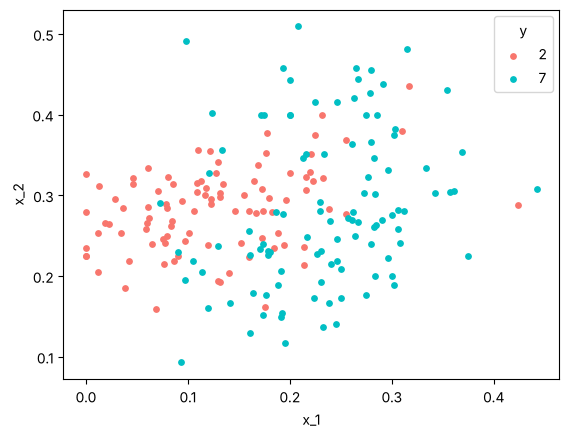

In [2]:
for digit, color in [("2", "#F8766D"), ("7", "#00BFC4")]:
    d = test[test["y"] == digit]
    plt.scatter(d["x_1"], d["x_2"], c=color, label=digit, s=15)
plt.xlabel("x_1"); plt.ylabel("x_2"); plt.legend(title="y")
plt.show()

In [3]:
knn_fit = KNeighborsClassifier(n_neighbors=5).fit(X_train, y_train)
y_hat_knn = knn_fit.predict(X_test)
accuracy_score(y_test, y_hat_knn)

0.815

A helper to plot an estimated conditional probability $p(x_1, x_2) = \Pr(Y=7 \mid x_1, x_2)$ over the `true_p` grid, with the 0.5 decision boundary:

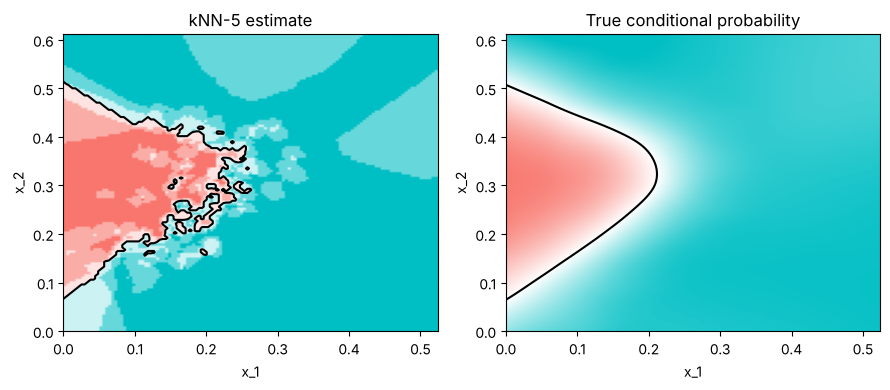

In [4]:
from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list("rb", ["#F8766D", "white", "#00BFC4"])

xs = np.sort(true_p["x_1"].unique())
ys = np.sort(true_p["x_2"].unique())
grid = true_p.sort_values(["x_2", "x_1"])          # row-major for reshaping
X_grid = grid[["x_1", "x_2"]]

def plot_cond_prob(p_hat=None, ax=None, title=""):
    p = grid["p"].to_numpy() if p_hat is None else np.asarray(p_hat)
    Z = p.reshape(len(ys), len(xs))
    ax = ax or plt.gca()
    ax.imshow(Z, origin="lower", extent=[xs.min(), xs.max(), ys.min(), ys.max()],
              cmap=cmap, vmin=0, vmax=1, aspect="auto")
    ax.contour(xs, ys, Z, levels=[0.5], colors="black")
    ax.set_title(title); ax.set_xlabel("x_1"); ax.set_ylabel("x_2")

def p7(model):
    """Estimated Pr(Y = 7) on the grid."""
    return model.predict_proba(X_grid)[:, list(model.classes_).index("7")]

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
plot_cond_prob(p7(knn_fit), axes[0], "kNN-5 estimate")
plot_cond_prob(None, axes[1], "True conditional probability")
plt.tight_layout(); plt.show()

## Over-training
Accuracy on the training set is higher than on the test set:

In [5]:
print("train:", accuracy_score(y_train, knn_fit.predict(X_train)))
print("test: ", accuracy_score(y_test, knn_fit.predict(X_test)))

train: 0.85875
test:  0.815


With $k=1$, each point is its own nearest neighbor, so training accuracy is (nearly) perfect, but test accuracy drops:

In [6]:
knn_fit_1 = KNeighborsClassifier(n_neighbors=1).fit(X_train, y_train)
print("train:", accuracy_score(y_train, knn_fit_1.predict(X_train)))
print("test: ", accuracy_score(y_test, knn_fit_1.predict(X_test)))

train: 0.995
test:  0.81


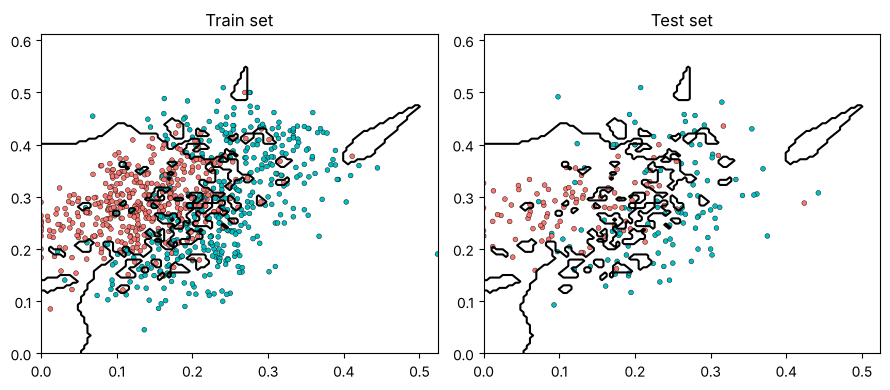

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
Z = p7(knn_fit_1).reshape(len(ys), len(xs))
for ax, d, title in [(axes[0], train, "Train set"), (axes[1], test, "Test set")]:
    ax.scatter(d["x_1"], d["x_2"], c=np.where(d["y"] == "7", "#00BFC4", "#F8766D"),
               s=12, edgecolors="black", linewidths=0.3)
    ax.contour(xs, ys, Z, levels=[0.5], colors="black")
    ax.set_title(title)
plt.tight_layout(); plt.show()

## Over-smoothing
With a very large $k$ the estimate is too smooth:

In [8]:
knn_fit_401 = KNeighborsClassifier(n_neighbors=401).fit(X_train, y_train)
accuracy_score(y_test, knn_fit_401.predict(X_test))

0.76

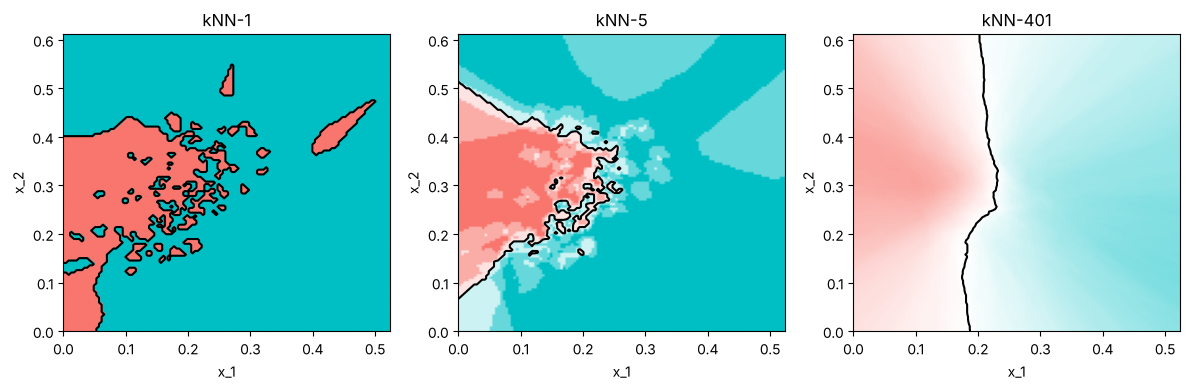

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, m, t in zip(axes, [knn_fit_1, knn_fit, knn_fit_401], ["kNN-1", "kNN-5", "kNN-401"]):
    plot_cond_prob(p7(m), ax, t)
plt.tight_layout(); plt.show()

## Picking the $k$ in kNN

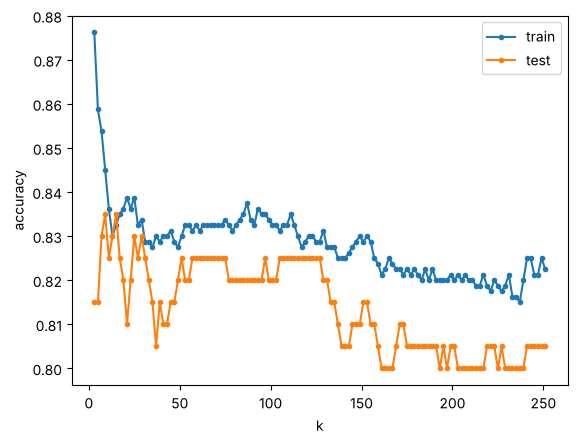

In [10]:
ks = np.arange(3, 252, 2)
rows = []
for k in ks:
    fit = KNeighborsClassifier(n_neighbors=k).fit(X_train, y_train)
    rows.append({"k": k,
                 "train": accuracy_score(y_train, fit.predict(X_train)),
                 "test": accuracy_score(y_test, fit.predict(X_test))})
accuracy = pd.DataFrame(rows)

plt.plot(accuracy["k"], accuracy["train"], "o-", ms=3, label="train")
plt.plot(accuracy["k"], accuracy["test"], "o-", ms=3, label="test")
plt.xlabel("k"); plt.ylabel("accuracy"); plt.legend()
plt.show()

In [11]:
best = accuracy.loc[accuracy["test"].idxmax()]
int(best["k"]), best["test"]

(9, np.float64(0.835))

**But** we just picked $k$ using the test set, so this accuracy estimate is over-optimistic. That's why we need cross-validation (next sections).

## Mathematical description of cross validation / K-fold cross validation
See the slides for the theory. In code, K-fold CV just splits the **training** set into $K$ folds and rotates which fold is held out:

In [12]:
kf = KFold(n_splits=10, shuffle=True, random_state=2008)
fold_acc = []
for tr_idx, va_idx in kf.split(X_train):
    fit = KNeighborsClassifier(n_neighbors=5).fit(X_train.iloc[tr_idx], y_train.iloc[tr_idx])
    fold_acc.append(accuracy_score(y_train.iloc[va_idx], fit.predict(X_train.iloc[va_idx])))
print(np.round(fold_acc, 3))
print("mean CV accuracy (k=5):", np.mean(fold_acc).round(3))

[0.862 0.688 0.85  0.862 0.75  0.788 0.8   0.8   0.85  0.812]
mean CV accuracy (k=5): 0.806


## Bootstrap
A skewed income distribution, where the population median is $m$:

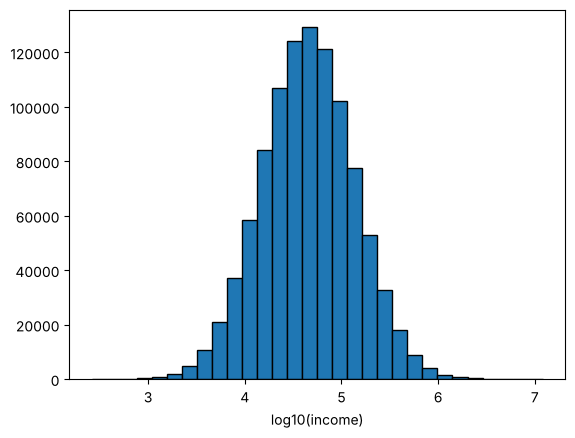

In [13]:
rng = np.random.default_rng(1995)
n = 10**6
income = 10 ** rng.normal(np.log10(45000), np.log10(3), n)
plt.hist(np.log10(income), bins=30, edgecolor="black")
plt.xlabel("log10(income)")
plt.show()

In [14]:
m = np.median(income)
m

np.float64(44976.6462977027)

In [15]:
N = 100
X = rng.choice(income, N, replace=False)
np.median(X)

np.float64(54890.29809317388)

Monte Carlo: the sampling distribution of the median (possible here only because we know the population).

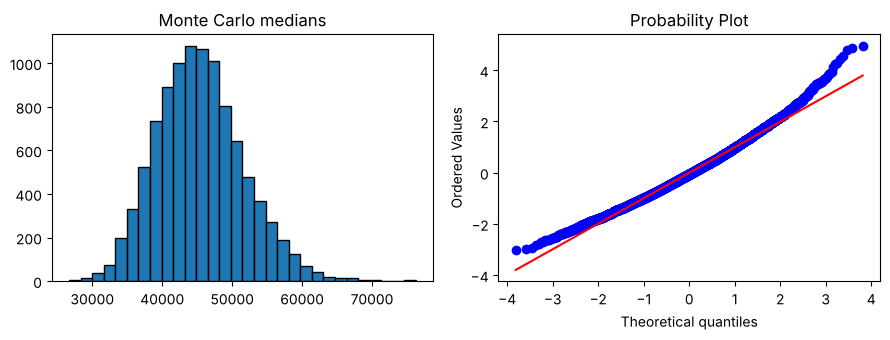

In [16]:
from scipy import stats
B = 10**4
M = np.array([np.median(rng.choice(income, N, replace=False)) for _ in range(B)])

fig, axes = plt.subplots(1, 2, figsize=(9, 3.5))
axes[0].hist(M, bins=30, edgecolor="black"); axes[0].set_title("Monte Carlo medians")
stats.probplot((M - M.mean()) / M.std(), dist="norm", plot=axes[1])
plt.tight_layout(); plt.show()

A CLT-based interval is not appropriate for the median:

In [17]:
np.median(X) + 1.96 * np.std(X, ddof=1) / np.sqrt(N) * np.array([-1, 1])

array([38871.79653111, 70908.79965524])

Compare with the actual (Monte Carlo) interval:

In [18]:
np.quantile(M, [0.025, 0.975])

array([34354.2499736 , 58638.53350419])

The **bootstrap**: resample the *sample* with replacement to mimic the sampling distribution.

In [19]:
M_star = np.array([np.median(rng.choice(X, N, replace=True)) for _ in range(B)])
np.quantile(M_star, [0.025, 0.975])

array([39674.29554719, 75184.68391688])

## The caret package → scikit-learn
`caret::train` provides one interface to hundreds of models. scikit-learn's equivalent is its consistent **estimator** API: every model has `.fit()`, `.predict()`, and `.predict_proba()`. (We'll do a full caret ↔ scikit-learn side-by-side in week 2.)

| caret | scikit-learn |
|---|---|
| `train(y ~ ., method = "glm")` | `LogisticRegression().fit(X, y)` |
| `train(y ~ ., method = "knn")` | `KNeighborsClassifier().fit(X, y)` |
| `predict(fit, newdata, type = "raw")` | `fit.predict(X_new)` |
| `predict(..., type = "prob")` | `fit.predict_proba(X_new)` |
| `tuneGrid`, `trainControl(method = "cv")` | `GridSearchCV(param_grid=..., cv=...)` |
| `fit$bestTune`, `fit$results` | `.best_params_`, `.cv_results_` |


In [20]:
train_glm = LogisticRegression(C=np.inf).fit(X_train, y_train)   # no penalty = plain GLM, like R
train_knn = KNeighborsClassifier().fit(X_train, y_train)              # default k = 5

y_hat_glm = train_glm.predict(X_test)
y_hat_knn = train_knn.predict(X_test)
print("glm:", accuracy_score(y_test, y_hat_glm))
print("knn:", accuracy_score(y_test, y_hat_knn))

glm: 0.775
knn: 0.815


## Cross validation with `GridSearchCV`
The equivalent of `train(..., tuneGrid = data.frame(k = seq(9, 71, 2)), trControl = trainControl(method = "cv", number = 10))`:

In [21]:
cv10 = KFold(n_splits=10, shuffle=True, random_state=2008)
train_knn_cv = GridSearchCV(KNeighborsClassifier(),
                            param_grid={"n_neighbors": np.arange(9, 72, 2)},
                            cv=cv10, scoring="accuracy")
train_knn_cv.fit(X_train, y_train)
train_knn_cv.best_params_

{'n_neighbors': np.int64(59)}

`cv_results_` is the analog of `train_knn$results`, including the SD across folds:

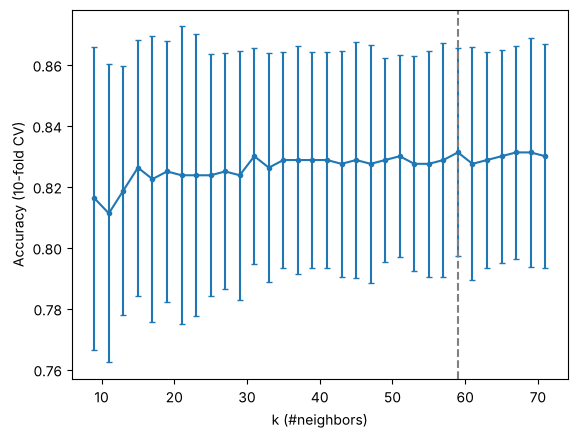

In [22]:
res = pd.DataFrame(train_knn_cv.cv_results_)[["param_n_neighbors", "mean_test_score", "std_test_score"]]
res.columns = ["k", "Accuracy", "AccuracySD"]

plt.errorbar(res["k"].astype(int), res["Accuracy"], yerr=res["AccuracySD"], fmt="o-", capsize=2, ms=3)
best_k = train_knn_cv.best_params_["n_neighbors"]
plt.axvline(best_k, color="gray", ls="--")
plt.xlabel("k (#neighbors)"); plt.ylabel("Accuracy (10-fold CV)")
plt.show()

By default `GridSearchCV` refits the best model on the full training set (`best_estimator_`, like `finalModel`). Now, and only now, we evaluate on the test set:

In [23]:
accuracy_score(y_test, train_knn_cv.predict(X_test))

0.825

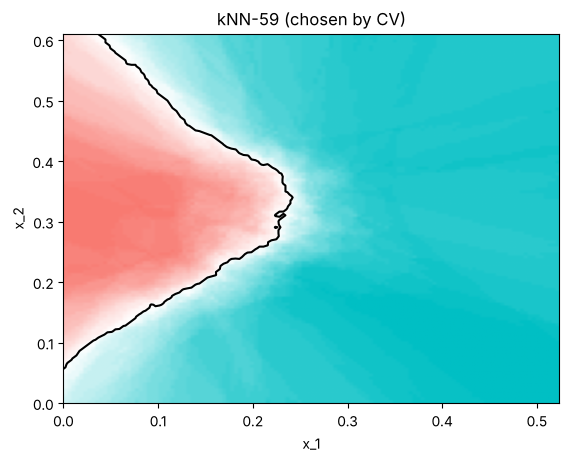

In [24]:
plot_cond_prob(p7(train_knn_cv.best_estimator_), title=f"kNN-{best_k} (chosen by CV)")
plt.show()

## Example: fitting with loess
caret's `gamLoess` fits a GAM with loess smoothers. Python has no direct loess-GAM classifier, so we use **`pygam.LogisticGAM`**, which uses penalized splines instead. The smoothing knob is `lam` (larger = smoother), playing the role of loess `span`.

Install once if needed: `pip install pygam`

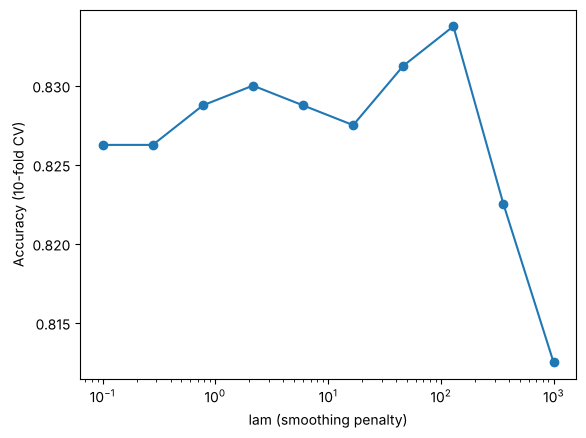

In [25]:
from pygam import LogisticGAM, s
import warnings; warnings.filterwarnings("ignore", category=RuntimeWarning)   # harmless pygam numerics

yb_train = (y_train == "7").astype(int)     # pygam wants 0/1
lams = np.logspace(-1, 3, 10)
gam_cv = []
for lam in lams:
    accs = []
    for tr_idx, va_idx in cv10.split(X_train):
        g = LogisticGAM(s(0, lam=lam) + s(1, lam=lam)).fit(X_train.iloc[tr_idx], yb_train.iloc[tr_idx])
        accs.append(np.mean(g.predict(X_train.iloc[va_idx]) == yb_train.iloc[va_idx]))
    gam_cv.append(np.mean(accs))

plt.semilogx(lams, gam_cv, "o-")
plt.xlabel("lam (smoothing penalty)"); plt.ylabel("Accuracy (10-fold CV)")
plt.show()

In [26]:
best_lam = lams[int(np.argmax(gam_cv))]
train_gam = LogisticGAM(s(0, lam=best_lam) + s(1, lam=best_lam)).fit(X_train, yb_train)
accuracy_score((y_test == "7").astype(int), train_gam.predict(X_test))

0.82

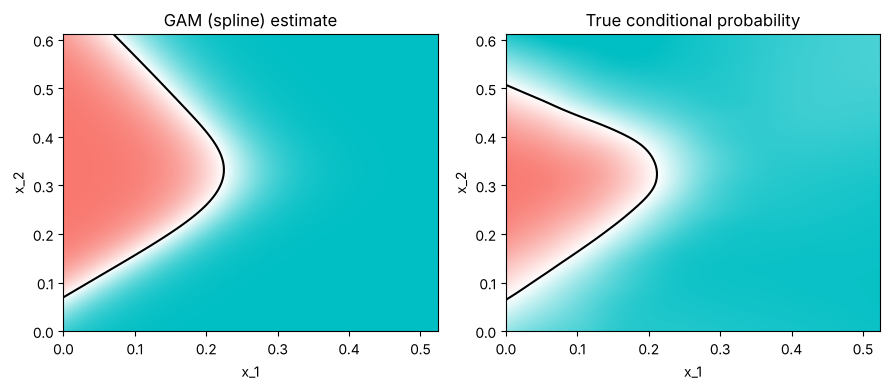

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
plot_cond_prob(train_gam.predict_proba(X_grid), axes[0], "GAM (spline) estimate")
plot_cond_prob(None, axes[1], "True conditional probability")
plt.tight_layout(); plt.show()

## Application: developing a TB biomarker
The TB NanoString data: 179 people, 107 genes, so $p$ is close to $N$. Tune kNN on all genes by 10-fold CV with AUC, then check the test set. Scaling goes **inside** the pipeline, so each CV fold is scaled using only its training data (like caret's `preProcess`).

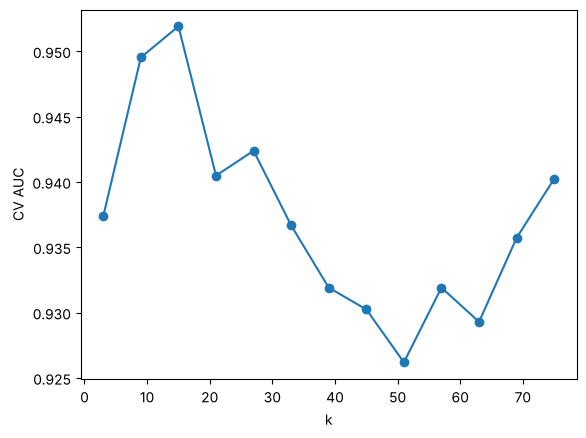

best k: {'kneighborsclassifier__n_neighbors': 15} | CV AUC: 0.952
test AUC: 0.938


In [28]:
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, confusion_matrix

tb = pd.read_csv(DATA + "TBnanostring.csv")
X_tb = tb.drop(columns="TB_Status"); y_tb = (tb["TB_Status"] == "TB").astype(int)
Xtr, Xte, ytr, yte = train_test_split(X_tb, y_tb, test_size=0.3, stratify=y_tb, random_state=1)

knn_cv = GridSearchCV(make_pipeline(StandardScaler(), KNeighborsClassifier()),
                      {"kneighborsclassifier__n_neighbors": list(range(3, 76, 6))},
                      cv=StratifiedKFold(10, shuffle=True, random_state=1), scoring="roc_auc")
knn_cv.fit(Xtr, ytr)
res = pd.DataFrame(knn_cv.cv_results_)
plt.plot(res["param_kneighborsclassifier__n_neighbors"], res["mean_test_score"], "o-")
plt.xlabel("k"); plt.ylabel("CV AUC"); plt.show()
print("best k:", knn_cv.best_params_, "| CV AUC:", round(knn_cv.best_score_, 3))
print("test AUC:", round(roc_auc_score(yte, knn_cv.predict_proba(Xte)[:, 1]), 3))

## A common pitfall: selecting genes before CV
Shuffle the labels so **no** gene is related to TB status. Selecting the top 10 genes using all samples, then cross-validating, still gives an AUC well above 0.5: **selection bias** (Ambroise & McLachlan, 2002). Selecting inside each training fold gives the honest answer, about 0.5.

In [29]:
from scipy.stats import ttest_ind
Xs = StandardScaler().fit_transform(X_tb)

def score_cv(X, y, inside, ntop=10, seed=0):
    def pick(Xa, ya):
        t = ttest_ind(Xa[ya == 1], Xa[ya == 0], equal_var=False).statistic
        top = np.argsort(-np.abs(t))[:ntop]
        return top, np.sign(t[top])
    p = np.zeros(len(y))
    if not inside:
        top, sgn = pick(X, y)                       # WRONG: uses all samples
    for tr_i, te_i in StratifiedKFold(5, shuffle=True, random_state=seed).split(X, y):
        if inside:
            top, sgn = pick(X[tr_i], y[tr_i])       # RIGHT: training folds only
        p[te_i] = X[np.ix_(te_i, top)] @ sgn
    return roc_auc_score(y, p)

rng = np.random.default_rng(1)
y_arr = y_tb.to_numpy()
res = np.array([[score_cv(Xs, ys, False, seed=r), score_cv(Xs, ys, True, seed=r)]
                for r, ys in enumerate(rng.permutation(y_arr) for _ in range(20))])
print("shuffled labels, selection outside CV:", res[:, 0].mean().round(2))
print("shuffled labels, selection inside CV: ", res[:, 1].mean().round(2))
print("real labels, selection inside CV:     ", round(score_cv(Xs, y_arr, True), 2))

shuffled labels, selection outside CV: 0.64
shuffled labels, selection inside CV:  0.5
real labels, selection inside CV:      0.93


**Lessons:** every data-driven step (gene selection, scaling, tuning) goes inside the CV loop (in scikit-learn, put it in a `Pipeline`); keep the test set untouched until the model is locked; then validate in an independent cohort.

## Session info

In [30]:
import sys, sklearn, matplotlib, scipy, pygam
print("Python", sys.version.split()[0])
print("numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__,
      "| scipy", scipy.__version__, "| pygam", pygam.__version__, "| matplotlib", matplotlib.__version__)

Python 3.13.18
numpy 2.5.3 | pandas 3.0.5 | scikit-learn 1.9.1 | scipy 1.16.3 | pygam 0.12.0 | matplotlib 3.11.2
